# Análise por município: desmatamento x focos de queimada (Pará)

Lê o painel município x ano PRODES (`dw.vw_comparativo_municipio_ano`, 2009–2025) e gera tabelas e gráficos em `figuras/`.
Os limites municipais são os da malha de 2025, aplicados a todos os anos.

**Antes de rodar:** as dependências do notebook anterior (`matplotlib`, `ipykernel`) e o kernel `.venv` selecionado.

In [2]:
import os
import textwrap
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from dotenv import load_dotenv, find_dotenv
from sqlalchemy import create_engine, text

load_dotenv(find_dotenv(usecwd=True))

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PASTA_FIGURAS = RAIZ / "figuras"
PASTA_FIGURAS.mkdir(exist_ok=True)
(RAIZ / "data" / "processed").mkdir(parents=True, exist_ok=True)

COR_DESMAT = "#0072B2"
COR_FOGO = "#D55E00"
FONTE = ("Fontes: INPE/PRODES (Amazônia Legal, v20260717), INPE/BDQueimadas (AQUA_M-T) e malha municipal 2025. "
         "Ano PRODES = agosto/(N-1) a julho/N; 2009–2025.")

plt.rcParams.update({
    "font.size": 13,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
})


def rodape(fig, texto=FONTE, tamanho=9):
    # rodapé com quebra de linha, para não ser cortado na borda da figura
    largura = int(fig.get_figwidth() * 11)
    fig.text(0.01, 0.01, textwrap.fill(texto, largura), fontsize=tamanho, color="gray", va="bottom")


def milhar(valor, _posicao=None):
    if valor >= 1:
        return f"{valor:,.0f}".replace(",", ".")
    return f"{valor:g}".replace(".", ",")

In [3]:
engine = create_engine(os.environ["DATABASE_URL"])
painel = pd.read_sql(text(
    "SELECT municipio, ano, area_desmatada_km2, qtd_focos, cod_ibge, area_municipio_km2 "
    "FROM dw.vw_comparativo_municipio_ano ORDER BY cod_ibge, ano"), engine)
painel = painel.astype({"ano": int, "area_desmatada_km2": float, "qtd_focos": int,
                        "cod_ibge": int, "area_municipio_km2": float})
print(painel.shape, "| municípios:", painel["municipio"].nunique(), "| anos:", painel["ano"].min(), "a", painel["ano"].max())

(2448, 6) | municípios: 144 | anos: 2009 a 2025


## 1. Totais por município (2009–2025)

In [4]:
tot = (painel.groupby(["cod_ibge", "municipio", "area_municipio_km2"], as_index=False)
             .agg(desmat_km2=("area_desmatada_km2", "sum"), focos=("qtd_focos", "sum")))
tot["pct_territorio_desmatado"] = 100 * tot["desmat_km2"] / tot["area_municipio_km2"]
tot["focos_por_100km2_territorio"] = 100 * tot["focos"] / tot["area_municipio_km2"]
tot["focos_por_km2_desmatado"] = (tot["focos"] / tot["desmat_km2"]).where(tot["desmat_km2"] > 0)

tot.to_csv(RAIZ / "data" / "processed" / "municipios_totais.csv", index=False)
tot.sort_values("desmat_km2", ascending=False).head(15).round(1).reset_index(drop=True)

,cod_ibge,municipio,area_municipio_km2,desmat_km2,focos,pct_territorio_desmatado,focos_por_100km2_territorio,focos_por_km2_desmatado
0,1500602,Altamira,159533.3,6398.3,53378,4.0,33.5,8.3
1,1507300,São Félix do Xingu,84212.9,5393.9,67553,6.4,80.2,12.5
2,1505031,Novo Progresso,38162.0,2799.1,32435,7.3,85.0,11.6
3,1505486,Pacajá,11832.3,2710.3,17677,22.9,149.4,6.5
4,1503606,Itaituba,62042.4,2609.4,24154,4.2,38.9,9.3
5,1505064,Novo Repartimento,15398.7,2432.5,13587,15.8,88.2,5.6
6,1505809,Portel,25386.2,2204.7,17536,8.7,69.1,8.0
7,1508159,Uruará,10791.4,1541.3,10722,14.3,99.4,7.0
8,1500859,Anapu,11895.3,1495.6,8196,12.6,68.9,5.5
9,1507805,Senador José Porfírio,14419.9,1339.2,6475,9.3,44.9,4.8


## 2. Concentração do desmatamento

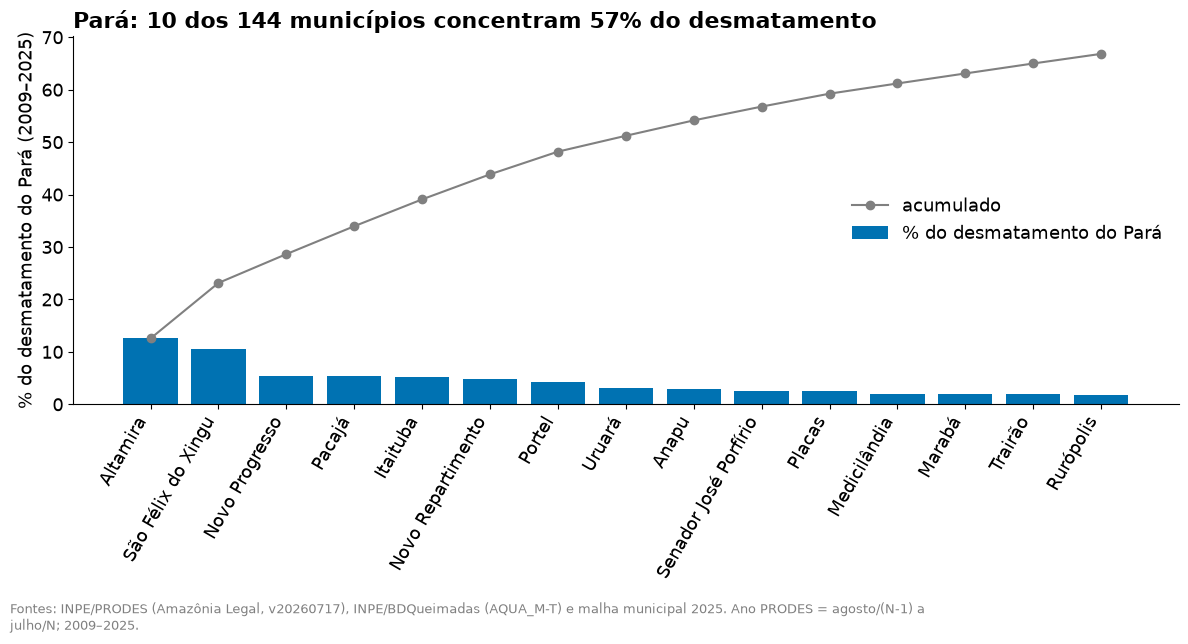

Os 10 maiores municípios em desmatamento têm 56.8% do desmatamento e 39.1% dos focos do estado.


In [5]:
ordenado = tot.sort_values("desmat_km2", ascending=False).reset_index(drop=True)
ordenado["parcela_pct"] = 100 * ordenado["desmat_km2"] / ordenado["desmat_km2"].sum()
ordenado["acumulada_pct"] = ordenado["parcela_pct"].cumsum()
top = ordenado.head(15)
parcela_top10 = ordenado.loc[:9, "parcela_pct"].sum()
focos_top10 = 100 * ordenado.loc[:9, "focos"].sum() / ordenado["focos"].sum()

fig, ax = plt.subplots(figsize=(12, 6.5))
posicoes = range(len(top))
ax.bar(posicoes, top["parcela_pct"], color=COR_DESMAT, label="% do desmatamento do Pará")
ax.plot(posicoes, top["acumulada_pct"], color="gray", marker="o", label="acumulado")
ax.set_xticks(list(posicoes))
ax.set_xticklabels(top["municipio"], rotation=60, ha="right")
ax.set_ylabel("% do desmatamento do Pará (2009–2025)")
ax.set_title(f"Pará: 10 dos {len(ordenado)} municípios concentram {parcela_top10:.0f}% do desmatamento",
             loc="left")
ax.legend(frameon=False, loc="center right")

rodape(fig)
fig.tight_layout(rect=(0, 0.06, 1, 1))
fig.savefig(PASTA_FIGURAS / "05_concentracao_municipios.png", dpi=200)
plt.show()
print(f"Os 10 maiores municípios em desmatamento têm {parcela_top10:.1f}% do desmatamento e {focos_top10:.1f}% dos focos do estado.")

## 3. Entre municípios: quem desmata mais também queima mais?
Cada ponto é um município (totais de 2009–2025), em escala logarítmica. Só entram municípios com desmatamento e focos acima de zero.

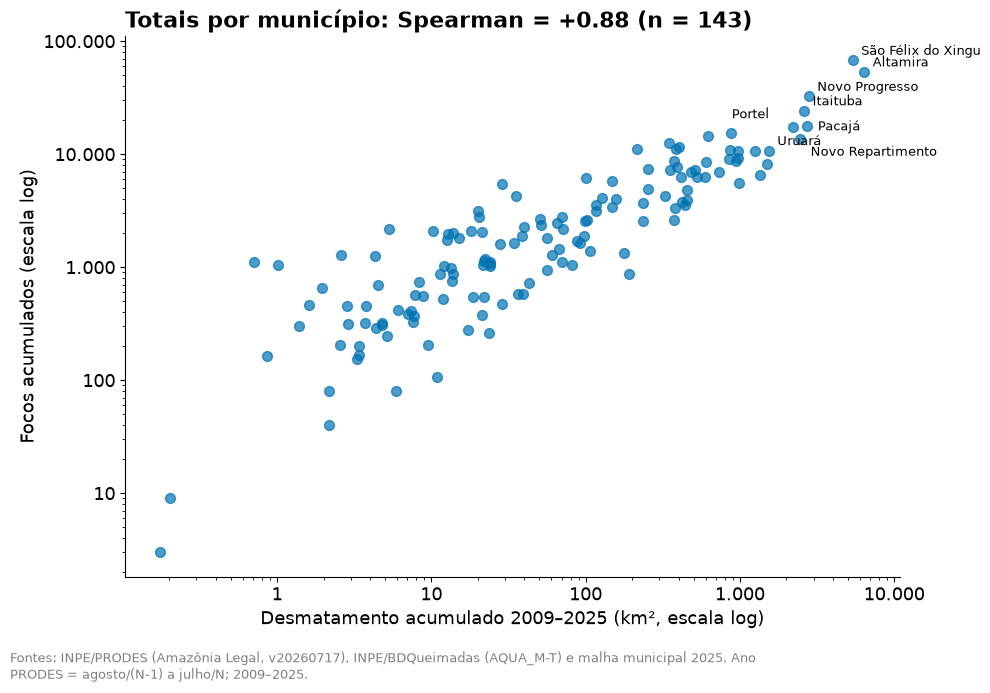

In [6]:
v = tot[(tot["desmat_km2"] > 0) & (tot["focos"] > 0)]
rho = v["desmat_km2"].rank().corr(v["focos"].rank())

fig, ax = plt.subplots(figsize=(10, 7))
ax.scatter(v["desmat_km2"], v["focos"], s=50, color=COR_DESMAT, alpha=0.7, zorder=3)
ax.set_xscale("log")
ax.set_yscale("log")
AJUSTE_ROTULO = {"Portel": (-44, 6), "Pacajá": (8, -3), "Novo Repartimento": (8, -12)}
for _, r in v.nlargest(8, "desmat_km2").iterrows():
    ax.annotate(r["municipio"], (r["desmat_km2"], r["focos"]), textcoords="offset points",
                xytext=AJUSTE_ROTULO.get(r["municipio"], (6, 4)), fontsize=9)
ax.set_xlabel("Desmatamento acumulado 2009–2025 (km², escala log)")
ax.set_ylabel("Focos acumulados (escala log)")
ax.xaxis.set_major_formatter(FuncFormatter(milhar))
ax.yaxis.set_major_formatter(FuncFormatter(milhar))
ax.set_title(f"Totais por município: Spearman = {rho:+.2f} (n = {len(v)})", loc="left")

rodape(fig)
fig.tight_layout(rect=(0, 0.06, 1, 1))
fig.savefig(PASTA_FIGURAS / "06_dispersao_municipios.png", dpi=200)
plt.show()

### 3b. Descontando o tamanho do município
Municípios grandes têm mais desmatamento e mais focos só por terem mais área. Aqui cada município entra em proporção ao seu território:
percentual da área desmatada (2009–2025) contra focos por 100 km².

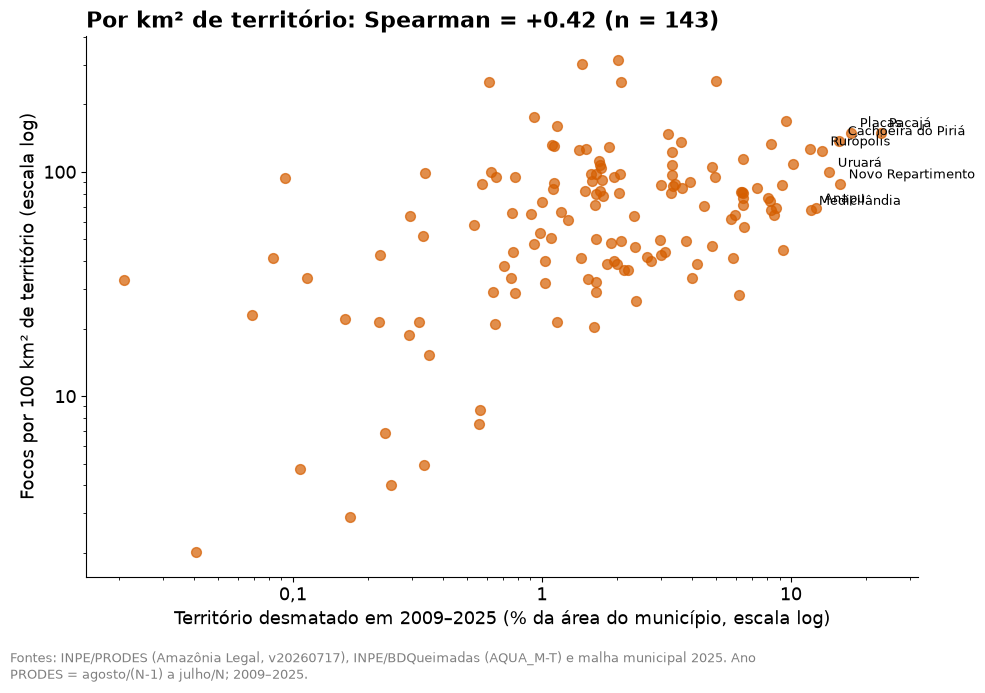

Spearman em totais: +0.88 | Spearman em proporção ao território: +0.42


In [7]:
d = tot[(tot["pct_territorio_desmatado"] > 0) & (tot["focos_por_100km2_territorio"] > 0)]
rho_dens = d["pct_territorio_desmatado"].rank().corr(d["focos_por_100km2_territorio"].rank())

fig, ax = plt.subplots(figsize=(10, 7))
ax.scatter(d["pct_territorio_desmatado"], d["focos_por_100km2_territorio"],
           s=50, color=COR_FOGO, alpha=0.7, zorder=3)
ax.set_xscale("log")
ax.set_yscale("log")
for _, r in d.nlargest(8, "pct_territorio_desmatado").iterrows():
    ax.annotate(r["municipio"], (r["pct_territorio_desmatado"], r["focos_por_100km2_territorio"]),
                textcoords="offset points", xytext=(6, 4), fontsize=9)
ax.set_xlabel("Território desmatado em 2009–2025 (% da área do município, escala log)")
ax.set_ylabel("Focos por 100 km² de território (escala log)")
ax.xaxis.set_major_formatter(FuncFormatter(milhar))
ax.yaxis.set_major_formatter(FuncFormatter(milhar))
ax.set_title(f"Por km² de território: Spearman = {rho_dens:+.2f} (n = {len(d)})", loc="left")

rodape(fig)
fig.tight_layout(rect=(0, 0.06, 1, 1))
fig.savefig(PASTA_FIGURAS / "06b_dispersao_densidade.png", dpi=200)
plt.show()
print(f"Spearman em totais: {rho:+.2f} | Spearman em proporção ao território: {rho_dens:+.2f}")

## 4. Dentro de cada município: os dois variam juntos ao longo dos anos?
Correlação de postos (Spearman) entre desmatamento e focos nos 17 anos, para os 15 municípios que mais desmataram.
Com 17 pontos por município, cada coeficiente é bastante incerto.

c:\Users\davic\VS code\Projetos profissionais\desmatamentos-queimadas-para\.venv\Lib\site-packages\numpy\lib\_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
c:\Users\davic\VS code\Projetos profissionais\desmatamentos-queimadas-para\.venv\Lib\site-packages\numpy\lib\_function_base_impl.py:3038: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


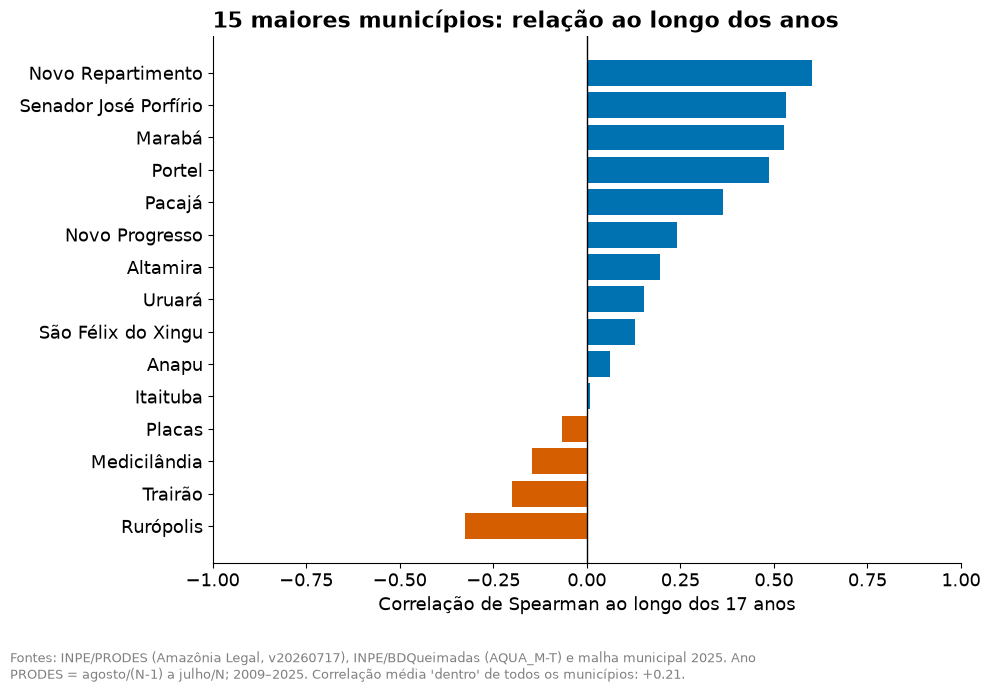

Correlação 'dentro' dos municípios (séries padronizadas): +0.21


In [8]:
linhas = []
for (cod, nome), g in painel.groupby(["cod_ibge", "municipio"]):
    linhas.append({"cod_ibge": cod, "municipio": nome,
                   "rho": g["area_desmatada_km2"].rank().corr(g["qtd_focos"].rank())})
rho_mun = pd.DataFrame(linhas).merge(tot[["cod_ibge", "desmat_km2"]], on="cod_ibge")
top_rho = rho_mun.nlargest(15, "desmat_km2").sort_values("rho")

# correlação "dentro" de todos os municípios: cada série padronizada pela média e desvio do próprio município
for col, novo in (("area_desmatada_km2", "des_z"), ("qtd_focos", "foc_z")):
    painel[novo] = painel.groupby("cod_ibge")[col].transform(lambda s: (s - s.mean()) / s.std(ddof=0))
r_dentro = painel["des_z"].corr(painel["foc_z"])

fig, ax = plt.subplots(figsize=(10, 7))
cores = [COR_DESMAT if r >= 0 else COR_FOGO for r in top_rho["rho"]]
ax.barh(top_rho["municipio"], top_rho["rho"], color=cores)
ax.axvline(0, color="black", linewidth=1)
ax.set_xlim(-1, 1)
ax.set_xlabel("Correlação de Spearman ao longo dos 17 anos")
ax.set_title("15 maiores municípios: relação ao longo dos anos", loc="left")

rodape(fig, FONTE + f" Correlação média 'dentro' de todos os municípios: {r_dentro:+.2f}.")
fig.tight_layout(rect=(0, 0.08, 1, 1))
fig.savefig(PASTA_FIGURAS / "07_correlacao_por_municipio.png", dpi=200)
plt.show()
print(f"Correlação 'dentro' dos municípios (séries padronizadas): {r_dentro:+.2f}")

## 5. Mapas
Este bloco lê a malha municipal. Se falhar, o restante do notebook continua válido.

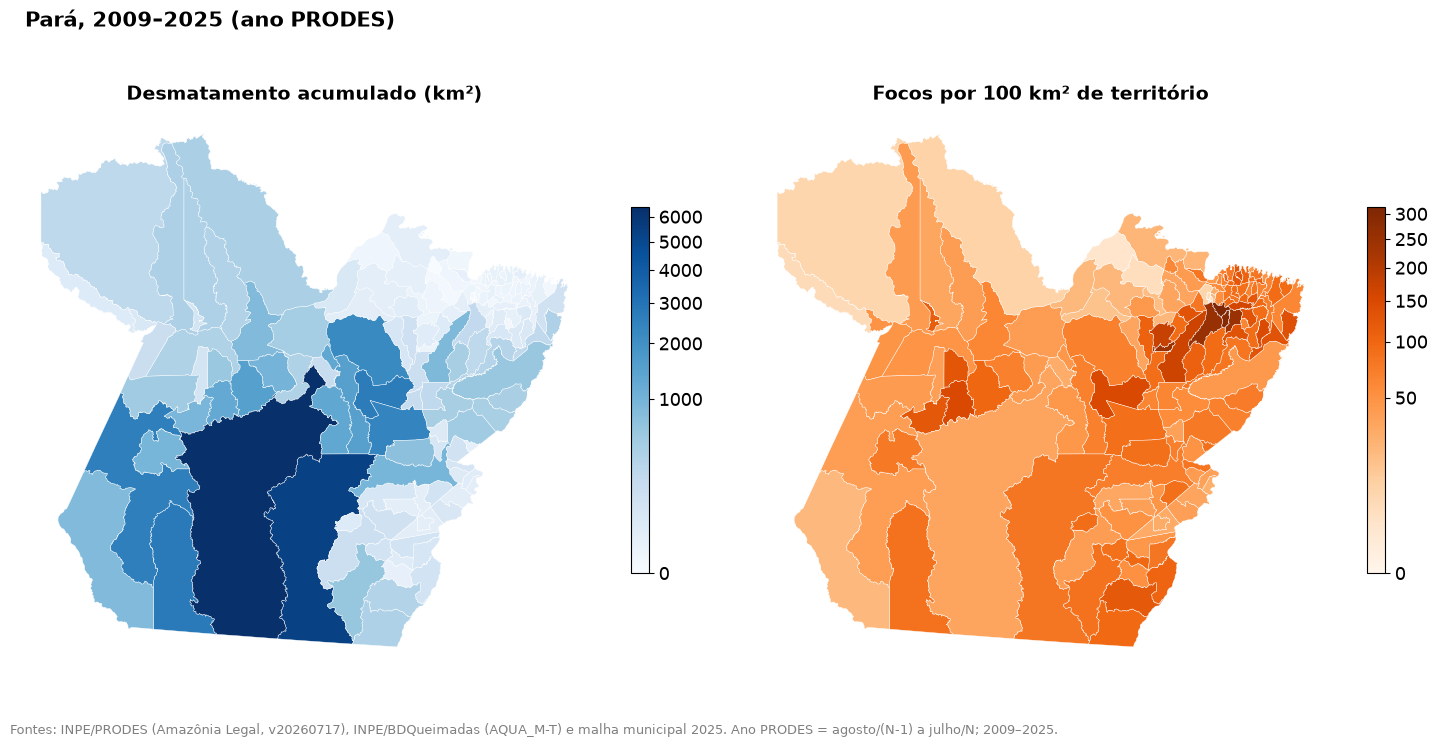

In [9]:
import geopandas as gpd
from matplotlib.colors import PowerNorm

malha = gpd.read_file(RAIZ / "data" / "raw" / "malha_municipal_para" / "PA_Municipios_2025.shp")
malha["cod_ibge"] = malha["CD_MUN"].astype(int)
mapa = malha.merge(tot[["cod_ibge", "desmat_km2", "focos_por_100km2_territorio"]], on="cod_ibge")

fig, eixos = plt.subplots(1, 2, figsize=(15, 7.5))
for ax, coluna, cmap, titulo in (
    (eixos[0], "desmat_km2", "Blues", "Desmatamento acumulado (km²)"),
    (eixos[1], "focos_por_100km2_territorio", "Oranges", "Focos por 100 km² de território"),
):
    mapa.plot(column=coluna, cmap=cmap, ax=ax, edgecolor="white", linewidth=0.3, legend=True,
              norm=PowerNorm(gamma=0.4, vmin=0, vmax=mapa[coluna].max()),
              legend_kwds={"shrink": 0.6})
    ax.set_title(titulo, fontsize=14)
    ax.set_axis_off()

fig.suptitle("Pará, 2009–2025 (ano PRODES)", fontsize=15, fontweight="bold", x=0.02, ha="left")
rodape(fig)
fig.tight_layout(rect=(0, 0.04, 1, 0.96))
fig.savefig(PASTA_FIGURAS / "08_mapas.png", dpi=200)
plt.show()

**Como ler estes resultados**
- Os limites municipais são os de 2025, aplicados a todos os anos; municípios criados ou alterados na série ficam com os limites atuais.
- Cada polígono do PRODES conta inteiro para o município do seu ponto representativo, e cada foco, para o município onde cai. Uma pequena parte (0,03% da área e 0,01% dos focos) ficou sem município.
- Focos de calor contam qualquer fogo, não só o associado a desmatamento novo.
- Com 17 anos por município, as correlações dentro de cada um descrevem os dados e não provam relação de causa.